# Sparse matrix-vector multiply (CSR SpMV): custom CUDA kernels vs cuSPARSE, plus cuTile

**What this measures**, on whatever NVIDIA GPU it runs on:
1. Five CSR SpMV implementations in CUDA C++ (scalar, warp-cooperative "vector" with 2 to 32 threads per row,
   and an adaptive kernel that bins rows by length and launches a specialized variant per bin), benchmarked
   against **cuSPARSE** (`cusparseSpMV`, default and CSR_ALG2) on classic **SuiteSparse** matrices and
   synthetic structured / unstructured / power-law matrices.
2. **Floating-point error analysis**: every result is checked against an FP64 reference, with error measured per
   row as `|y - y_ref| / (|A||x|)` in units of FP32 roundoff `u = 2^-24`.
3. A **cuTile Python** SpMV (tile-based CUDA DSL) that compiles one specialized kernel per row-length group.
   cuTile needs an Ampere-or-newer GPU (A100, L4, H100...). On a T4 that part is skipped.

**Where to run:** an A100 (ASU Sol) runs everything. Colab T4 runs parts 1 and 2 only.
Takes roughly 5 to 15 minutes, most of it downloading and reading SuiteSparse matrices.

Options (environment variables): `SPMV_SUITESPARSE=0` skips downloads, `SPMV_SCALE=0.25` shrinks the synthetic
matrices, `SPMV_SKIP_CUTILE=1` skips the cuTile part.

In [1]:
import os, sys, json, shutil, subprocess, pathlib, time, zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt

print(subprocess.run(["nvidia-smi", "--query-gpu=name,compute_cap,driver_version,memory.total",
                      "--format=csv,noheader"], capture_output=True, text=True).stdout.strip())
NVCC = shutil.which("nvcc")
print("nvcc:", NVCC)
SCALE = float(os.environ.get("SPMV_SCALE", "1.0"))
USE_SUITESPARSE = os.environ.get("SPMV_SUITESPARSE", "1") == "1"
SKIP_CUTILE = os.environ.get("SPMV_SKIP_CUTILE", "0") == "1"
WORK = pathlib.Path("spmv_work"); WORK.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]

NVIDIA A100-SXM4-80GB, 8.0, 615.71.09, 81920 MiB
nvcc: /packages/apps/spack/21/opt/spack/linux-rocky8-zen3/gcc-12.1.0/cuda-12.6.1-cf4xlcbcfpwchqwo5bktxyhjagryzcx6/bin/nvcc


## 1 · The CUDA C++ benchmark

In [2]:
%%writefile spmv_bench.cu
// spmv_bench.cu: CSR sparse matrix-vector multiply (y = A x, FP32) on NVIDIA GPUs.
//
// Kernels
//   scalar        one thread per row
//   vector<T>     T threads per row (T = 2..32), warp-shuffle reduction       (autotuning sweep)
//   adaptive      rows binned by length, each bin launched with its own kernel variant:
//                 short rows -> few threads, medium rows -> one warp, long rows -> one block
//   cuSPARSE      cusparseSpMV, ALG_DEFAULT and CSR_ALG2
//
// Every kernel is checked against an FP64 reference. Error is reported per row as
//   |y_i - y_ref_i| / (|A||x|)_i   in units of u = 2^-24 (FP32 unit roundoff),
// the componentwise measure used in floating-point error analysis of dot products.
//
// Timing: cold L2 (a large memset before every timed run), CUDA events, median of reps.
//
// Usage:  ./spmv_bench matrix.bin name          (binary CSR written by the notebook)
// Output: CSV-style lines on stdout prefixed with DEVICE, MATRIX, RESULT, ERRBUCKET.

#include <cuda_runtime.h>
#include <cusparse.h>

#include <algorithm>
#include <cmath>
#include <cstdint>
#include <cstdio>
#include <cstdlib>
#include <functional>
#include <string>
#include <vector>

#define CK(call)                                                                        \
  do {                                                                                  \
    cudaError_t e_ = (call);                                                            \
    if (e_ != cudaSuccess) {                                                            \
      fprintf(stderr, "CUDA error %s at %s:%d\n", cudaGetErrorString(e_), __FILE__,     \
              __LINE__);                                                                \
      exit(1);                                                                          \
    }                                                                                   \
  } while (0)
#define CS(call)                                                                        \
  do {                                                                                  \
    cusparseStatus_t s_ = (call);                                                       \
    if (s_ != CUSPARSE_STATUS_SUCCESS) {                                                \
      fprintf(stderr, "cuSPARSE error %d at %s:%d\n", (int)s_, __FILE__, __LINE__);     \
      exit(1);                                                                          \
    }                                                                                   \
  } while (0)

static const double kU = 5.9604644775390625e-08;  // 2^-24

// ------------------------------------------------------------------------------ kernels

__global__ void spmv_scalar(int n, const int* __restrict__ rp, const int* __restrict__ ci,
                            const float* __restrict__ v, const float* __restrict__ x,
                            float* __restrict__ y) {
  int r = blockIdx.x * blockDim.x + threadIdx.x;
  if (r < n) {
    float s = 0.f;
    for (int k = rp[r]; k < rp[r + 1]; ++k) s += v[k] * __ldg(&x[ci[k]]);
    y[r] = s;
  }
}

// T threads cooperate on one row; LIST = rows come from an index list (adaptive bins).
// No early return: every lane of every warp reaches the shuffles.
template <int T, bool LIST>
__global__ void spmv_vector(int n, const int* __restrict__ rows, const int* __restrict__ rp,
                            const int* __restrict__ ci, const float* __restrict__ v,
                            const float* __restrict__ x, float* __restrict__ y) {
  long long gid = (long long)blockIdx.x * blockDim.x + threadIdx.x;
  int i = (int)(gid / T);
  int lane = threadIdx.x & (T - 1);
  int r = 0;
  float s = 0.f;
  if (i < n) {
    r = LIST ? rows[i] : i;
    int e = rp[r + 1];
    for (int k = rp[r] + lane; k < e; k += T) s += v[k] * __ldg(&x[ci[k]]);
  }
#pragma unroll
  for (int off = T / 2; off > 0; off >>= 1) s += __shfl_down_sync(0xffffffffu, s, off, T);
  if (lane == 0 && i < n) y[r] = s;
}

// One block per (long) row: per-thread partial sums, then warp shuffles and shared memory.
template <int BS>
__global__ void spmv_block(int n, const int* __restrict__ rows, const int* __restrict__ rp,
                           const int* __restrict__ ci, const float* __restrict__ v,
                           const float* __restrict__ x, float* __restrict__ y) {
  __shared__ float warp_sums[BS / 32];
  int i = blockIdx.x;
  if (i >= n) return;  // uniform across the block
  int r = rows[i];
  int e = rp[r + 1];
  float s = 0.f;
  for (int k = rp[r] + threadIdx.x; k < e; k += BS) s += v[k] * __ldg(&x[ci[k]]);
#pragma unroll
  for (int off = 16; off > 0; off >>= 1) s += __shfl_down_sync(0xffffffffu, s, off);
  int w = threadIdx.x >> 5, l = threadIdx.x & 31;
  if (l == 0) warp_sums[w] = s;
  __syncthreads();
  if (w == 0) {
    s = (l < BS / 32) ? warp_sums[l] : 0.f;
#pragma unroll
    for (int off = 16; off > 0; off >>= 1) s += __shfl_down_sync(0xffffffffu, s, off);
    if (l == 0) y[r] = s;
  }
}

// FP64 reference and |A||x| for the componentwise error bound.
__global__ void spmv_ref64(int n, const int* __restrict__ rp, const int* __restrict__ ci,
                           const float* __restrict__ v, const float* __restrict__ x,
                           double* __restrict__ y, double* __restrict__ ay) {
  int r = blockIdx.x * blockDim.x + threadIdx.x;
  if (r < n) {
    double s = 0.0, a = 0.0;
    for (int k = rp[r]; k < rp[r + 1]; ++k) {
      double p = (double)v[k] * (double)x[ci[k]];
      s += p;
      a += fabs(p);
    }
    y[r] = s;
    ay[r] = a;
  }
}

template <int T>
static void launch_vec(unsigned grid, int rows, const int* list, const int* rp, const int* ci,
                       const float* v, const float* x, float* y) {
  if (list) spmv_vector<T, true><<<grid, 256>>>(rows, list, rp, ci, v, x, y);
  else      spmv_vector<T, false><<<grid, 256>>>(rows, list, rp, ci, v, x, y);
}

// ------------------------------------------------------------------------------ helpers

struct Csr {
  long long n = 0, m = 0, nnz = 0;
  std::vector<int> rp, ci;
  std::vector<float> v;
};

static Csr read_csr(const char* path) {
  FILE* f = fopen(path, "rb");
  if (!f) { fprintf(stderr, "cannot open %s\n", path); exit(1); }
  Csr A;
  long long h[3];
  if (fread(h, sizeof(long long), 3, f) != 3) { fprintf(stderr, "bad header\n"); exit(1); }
  A.n = h[0]; A.m = h[1]; A.nnz = h[2];
  A.rp.resize(A.n + 1); A.ci.resize(A.nnz); A.v.resize(A.nnz);
  size_t ok = fread(A.rp.data(), sizeof(int), A.n + 1, f);
  ok += fread(A.ci.data(), sizeof(int), A.nnz, f);
  ok += fread(A.v.data(), sizeof(float), A.nnz, f);
  fclose(f);
  if (ok != (size_t)(A.n + 1 + 2 * A.nnz)) { fprintf(stderr, "truncated file\n"); exit(1); }
  return A;
}

struct Timer {
  cudaEvent_t a, b;
  void* flush = nullptr;
  size_t flush_bytes;
  explicit Timer(size_t fb) : flush_bytes(fb) {
    CK(cudaEventCreate(&a)); CK(cudaEventCreate(&b));
    CK(cudaMalloc(&flush, flush_bytes));
  }
  // median and min of `reps` cold-L2 runs, in microseconds
  std::pair<double, double> time(const std::function<void()>& run, int reps) {
    run(); run();  // warm-up (also JIT / heuristics inside libraries)
    CK(cudaDeviceSynchronize());
    std::vector<double> t;
    for (int i = 0; i < reps; ++i) {
      CK(cudaMemsetAsync(flush, i & 0xff, flush_bytes));
      CK(cudaEventRecord(a));
      run();
      CK(cudaEventRecord(b));
      CK(cudaEventSynchronize(b));
      float ms = 0.f;
      CK(cudaEventElapsedTime(&ms, a, b));
      t.push_back(ms * 1e3);
    }
    std::sort(t.begin(), t.end());
    return {t[t.size() / 2], t[0]};
  }
};

// ------------------------------------------------------------------------------ main

int main(int argc, char** argv) {
  if (argc < 3) { fprintf(stderr, "usage: %s matrix.bin name\n", argv[0]); return 1; }
  const char* name = argv[2];
  Csr A = read_csr(argv[1]);
  const int n = (int)A.n, m = (int)A.m;
  const long long nnz = A.nnz;

  cudaDeviceProp prop;
  CK(cudaGetDeviceProperties(&prop, 0));

  // row-length statistics
  std::vector<int> len(n);
  long long maxlen = 0, empty = 0;
  double mean = (double)nnz / n, var = 0;
  for (int r = 0; r < n; ++r) {
    len[r] = A.rp[r + 1] - A.rp[r];
    maxlen = std::max<long long>(maxlen, len[r]);
    empty += (len[r] == 0);
    var += (len[r] - mean) * (len[r] - mean);
  }
  printf("MATRIX,%s,%d,%d,%lld,%.3f,%lld,%.3f,%lld\n", name, n, m, nnz, mean, maxlen,
         std::sqrt(var / n), empty);

  // deterministic x in [-1, 1)
  std::vector<float> hx(m);
  uint64_t seed = 0x9E3779B97F4A7C15ull;
  for (int j = 0; j < m; ++j) {
    seed = seed * 6364136223846793005ull + 1442695040888963407ull;
    hx[j] = (float)((double)(seed >> 11) / 9007199254740992.0 * 2.0 - 1.0);
  }

  int *d_rp, *d_ci;
  float *d_v, *d_x, *d_y;
  double *d_ref, *d_aref;
  CK(cudaMalloc(&d_rp, sizeof(int) * (n + 1)));
  CK(cudaMalloc(&d_ci, sizeof(int) * std::max<long long>(nnz, 1)));
  CK(cudaMalloc(&d_v, sizeof(float) * std::max<long long>(nnz, 1)));
  CK(cudaMalloc(&d_x, sizeof(float) * m));
  CK(cudaMalloc(&d_y, sizeof(float) * n));
  CK(cudaMalloc(&d_ref, sizeof(double) * n));
  CK(cudaMalloc(&d_aref, sizeof(double) * n));
  CK(cudaMemcpy(d_rp, A.rp.data(), sizeof(int) * (n + 1), cudaMemcpyHostToDevice));
  CK(cudaMemcpy(d_ci, A.ci.data(), sizeof(int) * nnz, cudaMemcpyHostToDevice));
  CK(cudaMemcpy(d_v, A.v.data(), sizeof(float) * nnz, cudaMemcpyHostToDevice));
  CK(cudaMemcpy(d_x, hx.data(), sizeof(float) * m, cudaMemcpyHostToDevice));

  // FP64 reference
  spmv_ref64<<<(n + 255) / 256, 256>>>(n, d_rp, d_ci, d_v, d_x, d_ref, d_aref);
  CK(cudaGetLastError());
  std::vector<double> ref(n), aref(n);
  CK(cudaMemcpy(ref.data(), d_ref, sizeof(double) * n, cudaMemcpyDeviceToHost));
  CK(cudaMemcpy(aref.data(), d_aref, sizeof(double) * n, cudaMemcpyDeviceToHost));

  // achievable DRAM bandwidth on this GPU: device-to-device copy of 512 MB
  size_t flush_bytes = std::max<size_t>((size_t)prop.l2CacheSize * 4, (size_t)256 << 20);
  Timer timer(flush_bytes);
  double copy_gbs = 0;
  {
    size_t cb = (size_t)256 << 20;
    void *s, *t;
    CK(cudaMalloc(&s, cb)); CK(cudaMalloc(&t, cb));
    auto r = timer.time([&] { CK(cudaMemcpyAsync(t, s, cb, cudaMemcpyDeviceToDevice)); }, 10);
    copy_gbs = 2.0 * cb / (r.first * 1e-6) / 1e9;
    CK(cudaFree(s)); CK(cudaFree(t));
  }
  printf("DEVICE,%s,%d,%d,%d.%d,%.1f\n", prop.name, prop.multiProcessorCount, prop.l2CacheSize,
         prop.major, prop.minor, copy_gbs);

  // compulsory traffic: values + column indices + row pointers + x (once) + y
  const double bytes = 8.0 * nnz + 4.0 * (n + 1) + 4.0 * m + 4.0 * n;

  // adaptive bins by row length
  const int kBins = 6;
  const int lim[kBins] = {4, 8, 16, 32, 2048, 1 << 30};  // inclusive upper bounds
  std::vector<std::vector<int>> bin(kBins);
  for (int r = 0; r < n; ++r) {
    int b = 0;
    while (len[r] > lim[b]) ++b;
    bin[b].push_back(r);
  }
  std::vector<int*> d_bin(kBins, nullptr);
  for (int b = 0; b < kBins; ++b) {
    if (bin[b].empty()) continue;
    CK(cudaMalloc(&d_bin[b], sizeof(int) * bin[b].size()));
    CK(cudaMemcpy(d_bin[b], bin[b].data(), sizeof(int) * bin[b].size(), cudaMemcpyHostToDevice));
  }
  int n_launch_adaptive = 0;
  for (int b = 0; b < kBins; ++b) n_launch_adaptive += !bin[b].empty();

  auto launch_vector = [&](int T, int rows, const int* list) {
    unsigned g = (unsigned)(((long long)rows * T + 255) / 256);
    if (g == 0) return;
    switch (T) {
      case 2:  launch_vec<2>(g, rows, list, d_rp, d_ci, d_v, d_x, d_y); break;
      case 4:  launch_vec<4>(g, rows, list, d_rp, d_ci, d_v, d_x, d_y); break;
      case 8:  launch_vec<8>(g, rows, list, d_rp, d_ci, d_v, d_x, d_y); break;
      case 16: launch_vec<16>(g, rows, list, d_rp, d_ci, d_v, d_x, d_y); break;
      default: launch_vec<32>(g, rows, list, d_rp, d_ci, d_v, d_x, d_y); break;
    }
  };

  struct Variant { std::string name; std::function<void()> run; int launches; };
  std::vector<Variant> variants;
  variants.push_back({"scalar", [&] {
    spmv_scalar<<<(n + 255) / 256, 256>>>(n, d_rp, d_ci, d_v, d_x, d_y); }, 1});
  for (int T : {2, 4, 8, 16, 32})
    variants.push_back({"vector" + std::to_string(T), [&, T] { launch_vector(T, n, nullptr); }, 1});
  variants.push_back({"adaptive", [&] {
    const int tpr[5] = {2, 4, 8, 16, 32};
    for (int b = 0; b < 5; ++b)
      if (!bin[b].empty()) launch_vector(tpr[b], (int)bin[b].size(), d_bin[b]);
    if (!bin[5].empty())
      spmv_block<256><<<(unsigned)bin[5].size(), 256>>>((int)bin[5].size(), d_bin[5], d_rp, d_ci,
                                                        d_v, d_x, d_y);
  }, n_launch_adaptive});

  // cuSPARSE with descriptors and workspace created once, outside the timed region
  cusparseHandle_t h;
  CS(cusparseCreate(&h));
  cusparseSpMatDescr_t matA;
  cusparseDnVecDescr_t vecX, vecY;
  CS(cusparseCreateCsr(&matA, n, m, nnz, d_rp, d_ci, d_v, CUSPARSE_INDEX_32I, CUSPARSE_INDEX_32I,
                       CUSPARSE_INDEX_BASE_ZERO, CUDA_R_32F));
  CS(cusparseCreateDnVec(&vecX, m, d_x, CUDA_R_32F));
  CS(cusparseCreateDnVec(&vecY, n, d_y, CUDA_R_32F));
  const float alpha = 1.f, beta = 0.f;
  struct Alg { const char* name; cusparseSpMVAlg_t alg; void* buf; };
  std::vector<Alg> algs = {{"cusparse_default", CUSPARSE_SPMV_ALG_DEFAULT, nullptr},
                           {"cusparse_csr_alg2", CUSPARSE_SPMV_CSR_ALG2, nullptr}};
  for (auto& a : algs) {
    size_t bs = 0;
    CS(cusparseSpMV_bufferSize(h, CUSPARSE_OPERATION_NON_TRANSPOSE, &alpha, matA, vecX, &beta,
                               vecY, CUDA_R_32F, a.alg, &bs));
    CK(cudaMalloc(&a.buf, std::max<size_t>(bs, 16)));
    Alg* ap = &a;
    variants.push_back({a.name, [&, ap] {
      CS(cusparseSpMV(h, CUSPARSE_OPERATION_NON_TRANSPOSE, &alpha, matA, vecX, &beta, vecY,
                      CUDA_R_32F, ap->alg, ap->buf));
    }, 1});
  }

  // run, time and check every variant
  std::vector<float> hy(n);
  for (auto& var : variants) {
    CK(cudaMemset(d_y, 0xFF, sizeof(float) * n));  // NaN: any row a kernel forgets shows up
    var.run();
    CK(cudaGetLastError());
    CK(cudaDeviceSynchronize());
    CK(cudaMemcpy(hy.data(), d_y, sizeof(float) * n, cudaMemcpyDeviceToHost));

    double max_err = 0, sum_err = 0;
    long long bad = 0;
    const int kB = 32;
    std::vector<double> bmax(kB, 0.0);
    std::vector<long long> bcnt(kB, 0);
    for (int r = 0; r < n; ++r) {
      double e;
      if (!std::isfinite(hy[r])) { e = INFINITY; ++bad; }
      else if (aref[r] == 0.0) e = (hy[r] == 0.f) ? 0.0 : INFINITY;
      else e = std::fabs((double)hy[r] - ref[r]) / aref[r] / kU;
      max_err = std::max(max_err, e);
      if (std::isfinite(e)) sum_err += e;
      int b = 0;
      while ((1 << (b + 1)) <= std::max(len[r], 1) && b < kB - 1) ++b;  // floor(log2(len))
      bmax[b] = std::max(bmax[b], e);
      ++bcnt[b];
    }

    int reps = 30;
    auto t = timer.time(var.run, reps);
    double us = t.first;
    printf("RESULT,%s,%s,%.3f,%.3f,%.3f,%.2f,%.4g,%.4g,%d,%lld\n", name, var.name.c_str(), us,
           t.second, 2.0 * nnz / (us * 1e-6) / 1e9, bytes / (us * 1e-6) / 1e9, max_err,
           sum_err / n, var.launches, bad);
    if (var.name == "scalar" || var.name == "vector32" || var.name == "adaptive" ||
        var.name == "cusparse_default")
      for (int b = 0; b < kB; ++b)
        if (bcnt[b]) printf("ERRBUCKET,%s,%s,%d,%lld,%.4g\n", name, var.name.c_str(), b, bcnt[b],
                            bmax[b]);
    fflush(stdout);
  }

  CS(cusparseDestroySpMat(matA));
  CS(cusparseDestroyDnVec(vecX));
  CS(cusparseDestroyDnVec(vecY));
  CS(cusparseDestroy(h));
  return 0;
}

Overwriting spmv_bench.cu


In [3]:
arch = "native"
cmd = [NVCC or "nvcc", "-O3", "-std=c++17", "-lineinfo", f"-arch={arch}", "spmv_bench.cu", "-o", "spmv_bench",
       "-lcusparse", "-Xptxas", "-v"]
p = subprocess.run(cmd, capture_output=True, text=True)
if p.returncode != 0:            # older nvcc without -arch=native: use the GPU's compute capability
    cc = subprocess.run(["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"],
                        capture_output=True, text=True).stdout.strip().split("\n")[0].replace(".", "")
    cmd[cmd.index(f"-arch={arch}")] = f"-arch=sm_{cc}"
    p = subprocess.run(cmd, capture_output=True, text=True)
print(p.stderr[-3000:] if p.returncode else "compiled spmv_bench")
assert p.returncode == 0, "compilation failed"
regs = [l.strip() for l in p.stderr.splitlines() if "registers" in l]
print(f"{len(regs)} kernel variants compiled; register use: {sorted(set(r.split('Used ')[1].split(',')[0] for r in regs))}")

compiled spmv_bench
13 kernel variants compiled; register use: ['27 registers', '32 registers']


## 2 · Matrix suite

In [4]:
%%writefile spmv_lib.py
"""Host-side helpers for the SpMV study: matrix suite, CSR I/O, result parsing, cuTile kernel."""

from __future__ import annotations

import io
import pathlib
import subprocess
import tarfile
import time
import urllib.request

import numpy as np
import pandas as pd
import scipy.io
import scipy.sparse as sp

# Classic SpMV benchmark matrices (Williams et al., Bell & Garland) plus a few irregular ones.
SUITESPARSE = [
    ("Williams", "cant", "FEM cantilever"),
    ("Williams", "pdb1HYS", "protein, dense rows"),
    ("Bova", "rma10", "3D CFD"),
    ("Williams", "cop20k_A", "FEM accelerator"),
    ("Williams", "consph", "FEM spheres"),
    ("Williams", "mac_econ_fwd500", "economics, irregular"),
    ("Hamm", "scircuit", "circuit, irregular"),
    ("Williams", "webbase-1M", "web graph, power law"),
]
MIRRORS = ["https://suitesparse-collection-website.herokuapp.com/MM/{g}/{n}.tar.gz",
           "https://sparse.tamu.edu/MM/{g}/{n}.tar.gz"]


def clean(A) -> sp.csr_matrix:
    A = sp.csr_matrix(A, dtype=np.float32)
    A.sum_duplicates()
    A.sort_indices()
    A.indptr = A.indptr.astype(np.int32)
    A.indices = A.indices.astype(np.int32)
    return A


# ------------------------------------------------------------------ synthetic matrices
def laplace2d(k: int) -> sp.csr_matrix:
    """5-point finite-difference Laplacian on a k x k grid (structured, 5 nnz/row)."""
    T = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(k, k))
    I = sp.identity(k)
    return clean(sp.kron(I, T) + sp.kron(T, I))


def stencil27(k: int, seed: int = 0) -> sp.csr_matrix:
    """27-point stencil on a k^3 grid with random weights (structured, 27 nnz/row)."""
    t = sp.diags([1.0, 1.0, 1.0], [-1, 0, 1], shape=(k, k))
    A = sp.kron(sp.kron(t, t), t).tocsr()
    A.data = np.random.default_rng(seed).uniform(0.5, 1.5, A.nnz)
    return clean(A)


def random_uniform(n: int, per_row: int, seed: int = 1) -> sp.csr_matrix:
    """Erdos-Renyi style: per_row random columns in every row (unstructured, no locality)."""
    rng = np.random.default_rng(seed)
    cols = np.sort(rng.integers(0, n, (n, per_row)), axis=1).ravel()
    indptr = np.arange(0, n * per_row + 1, per_row)
    return clean(sp.csr_matrix((rng.uniform(-1, 1, n * per_row), cols, indptr), shape=(n, n)))


def powerlaw(n: int, alpha: float = 1.5, scale: float = 4.0, cap: int = 50_000, seed: int = 2):
    """Heavy-tailed row lengths (graph-like): most rows short, a few with tens of thousands of
    nonzeros, and 1% empty rows to exercise the empty-row corner case."""
    rng = np.random.default_rng(seed)
    lens = np.minimum(np.floor(rng.pareto(alpha, n) * scale).astype(np.int64) + 1, cap)
    lens[rng.random(n) < 0.01] = 0
    indptr = np.concatenate([[0], np.cumsum(lens)])
    cols = rng.integers(0, n, int(indptr[-1]))
    return clean(sp.csr_matrix((rng.uniform(-1, 1, cols.size), cols, indptr), shape=(n, n)))


def synthetic_suite(scale: float = 1.0):
    s = lambda v: max(8, int(v * scale))  # noqa: E731
    return {
        "laplace2d": (laplace2d(s(1024)), "2D Poisson, 5-point"),
        "stencil27_3d": (stencil27(s(80)), "3D 27-point stencil"),
        "random_uniform": (random_uniform(s(1_000_000), 16), "random, 16/row"),
        "powerlaw": (powerlaw(s(1_000_000)), "synthetic power law"),
    }


# ------------------------------------------------------------------ SuiteSparse download
def fetch_suitesparse(group: str, name: str, folder: pathlib.Path, timeout: int = 120):
    """Load a SuiteSparse matrix from folder/<name>.mtx or folder/<name>.tar.gz (for example downloaded
    in a browser from sparse.tamu.edu and uploaded). If neither is there, try one plain download."""
    folder.mkdir(parents=True, exist_ok=True)
    mtx, tgz = folder / f"{name}.mtx", folder / f"{name}.tar.gz"
    if not mtx.exists():
        if not (tgz.exists() and tgz.stat().st_size > 0):
            last = None
            for m in MIRRORS:
                try:
                    with urllib.request.urlopen(m.format(g=group, n=name), timeout=timeout) as r:
                        tgz.write_bytes(r.read())
                    break
                except Exception as e:  # noqa: BLE001
                    last = e
            else:
                raise RuntimeError(f"not found locally and download failed ({last}); "
                                   f"download {name}.tar.gz in a browser and put it in {folder}/")
        with tarfile.open(tgz, mode="r:gz") as tf:
            member = next(m for m in tf.getmembers()
                          if m.name.endswith(f"/{name}.mtx") or m.name == f"{name}.mtx")
            mtx.write_bytes(tf.extractfile(member).read())
    return clean(scipy.io.mmread(str(mtx)))


# ------------------------------------------------------------------ CSR binary for the C++ bench
def write_bin(A: sp.csr_matrix, path: pathlib.Path):
    with open(path, "wb") as f:
        np.array([A.shape[0], A.shape[1], A.nnz], dtype=np.int64).tofile(f)
        A.indptr.astype(np.int32).tofile(f)
        A.indices.astype(np.int32).tofile(f)
        A.data.astype(np.float32).tofile(f)


def bench_x(m: int) -> np.ndarray:
    """Same deterministic x in [-1, 1) as spmv_bench.cu (64-bit LCG, top 53 bits)."""
    x = np.empty(m, dtype=np.float32)
    s = 0x9E3779B97F4A7C15
    mask = (1 << 64) - 1
    for j in range(m):
        s = (s * 6364136223846793005 + 1442695040888963407) & mask
        x[j] = np.float32((s >> 11) / 9007199254740992.0 * 2.0 - 1.0)
    return x


def bench_x_fast(m: int) -> np.ndarray:
    """Vectorized bench_x via the LCG jump-ahead (identical values, fast for millions)."""
    a, c, mask = 6364136223846793005, 1442695040888963407, (1 << 64) - 1
    s0 = 0x9E3779B97F4A7C15
    out = np.empty(m, dtype=np.uint64)
    # states s_j = A_j * s0 + C_j with A_j = a^j, C_j = c (a^j - 1)/(a - 1), all mod 2^64
    A, C = 1, 0
    block = min(m, 4096)
    Ab, Cb = [], []
    for _ in range(block):
        A, C = (A * a) & mask, (C * a + c) & mask
        Ab.append(A); Cb.append(C)
    Ab = np.array(Ab, dtype=np.uint64); Cb = np.array(Cb, dtype=np.uint64)
    s = s0
    for start in range(0, m, block):
        k = min(block, m - start)
        with np.errstate(over="ignore"):
            out[start:start + k] = Ab[:k] * np.uint64(s) + Cb[:k]
        s = int(out[start + k - 1])
    return ((out >> np.uint64(11)).astype(np.float64) / 9007199254740992.0 * 2.0 - 1.0).astype(np.float32)


# ------------------------------------------------------------------ run + parse
RESULT_COLS = ["matrix", "kernel", "us", "us_min", "gflops", "gbs", "max_err_u", "mean_err_u",
               "launches", "bad_rows"]


def run_bench(binary: str, path: pathlib.Path, name: str, timeout: int = 1800):
    p = subprocess.run([binary, str(path), name], capture_output=True, text=True, timeout=timeout)
    if p.returncode != 0:
        raise RuntimeError(f"{name}: spmv_bench failed\n{p.stderr[-2000:]}")
    return p.stdout


def parse(lines: str):
    res, err, mats, dev = [], [], [], None
    for ln in lines.splitlines():
        f = ln.strip().split(",")
        if f[0] == "RESULT":
            res.append(f[1:3] + [float(v) for v in f[3:9]] + [int(f[9]), int(f[10])])
        elif f[0] == "ERRBUCKET":
            err.append(dict(matrix=f[1], kernel=f[2], log2len=int(f[3]), rows=int(f[4]),
                            max_err_u=float(f[5])))
        elif f[0] == "MATRIX":
            mats.append(dict(matrix=f[1], rows=int(f[2]), cols=int(f[3]), nnz=int(f[4]),
                             mean_len=float(f[5]), max_len=int(f[6]), std_len=float(f[7]),
                             empty_rows=int(f[8])))
        elif f[0] == "DEVICE":
            dev = dict(name=f[1], sms=int(f[2]), l2=int(f[3]), cc=f[4], copy_gbs=float(f[5]))
    return pd.DataFrame(res, columns=RESULT_COLS), pd.DataFrame(err), pd.DataFrame(mats), dev


def cusp_tpr(mean_len: float) -> int:
    """Classic CSR-vector heuristic (CUSP): threads per row from the mean row length."""
    for t in (2, 4, 8, 16):
        if mean_len <= t:
            return t
    return 32


# ------------------------------------------------------------------ cuTile (Ampere or newer)
def cutile_groups(indptr: np.ndarray):
    """Rows grouped by row-length class. Each group gets a tile shape (R rows x W nonzeros)
    that cuTile compiles into its own specialized kernel."""
    lens = np.diff(indptr)
    p2 = np.maximum(4, 1 << np.ceil(np.log2(np.maximum(lens, 1))).astype(np.int64))
    p2 = np.minimum(p2, 4096)                 # everything longer shares one group
    groups = []
    for P in np.unique(p2):
        rows = np.nonzero(p2 == P)[0].astype(np.int32)
        W = int(min(P, 256))
        R = int(max(1, 1024 // W))
        groups.append(dict(rows=rows, W=W, R=R, max_len=int(lens[rows].max()), n=len(rows)))
    return groups


def emulate_cutile(indptr, indices, data, x, groups):
    """NumPy emulation of the cuTile kernel's tile logic (used to test the grouping on CPU)."""
    y = np.full(len(indptr) - 1, np.nan, dtype=np.float32)
    for g in groups:
        R, W = g["R"], g["W"]
        for blk in range(-(-g["n"] // R)):
            lane = blk * R + np.arange(R)
            rmask = lane < g["n"]
            rows = np.where(rmask, g["rows"][np.minimum(lane, g["n"] - 1)], 0)
            start, end = indptr[rows], indptr[rows + 1]
            acc = np.zeros(R, dtype=np.float32)
            off = np.arange(W)[None, :]
            for j in range(0, g["max_len"], W):
                k = start[:, None] + off + j
                m = (k < end[:, None]) & rmask[:, None]
                kk = np.where(m, k, 0)
                c = np.where(m, indices[kk], 0)
                v = np.where(m, data[kk], 0).astype(np.float32)
                xv = np.where(m, x[c], 0).astype(np.float32)
                acc = acc + (v * xv).sum(axis=1, dtype=np.float32)
            y[rows[rmask]] = acc[rmask]
    return y


Overwriting spmv_lib.py


In [5]:
import importlib, spmv_lib as L
importlib.reload(L)
mats = {}
for name, (A, desc) in L.synthetic_suite(SCALE).items():
    mats[name] = (A, desc, "synthetic")
if USE_SUITESPARSE:
    for group, name, desc in L.SUITESPARSE:
        t = time.time()
        try:
            mats[name] = (L.fetch_suitesparse(group, name, WORK / "mtx"), desc, "SuiteSparse")
            print(f"  {name:16s} loaded in {time.time() - t:5.1f}s")
        except Exception as e:
            print(f"  {name:16s} skipped: {str(e)[:100]}")
for name, (A, desc, src) in mats.items():
    L.write_bin(A, WORK / f"{name}.bin")
print(f"{len(mats)} matrices: {sum(v[2] == 'SuiteSparse' for v in mats.values())} SuiteSparse, "
      f"{sum(v[2] == 'synthetic' for v in mats.values())} synthetic")

  cant             loaded in   0.2s


  pdb1HYS          loaded in   0.2s
  rma10            loaded in   0.2s


  cop20k_A         loaded in   0.1s


  consph           loaded in   0.3s
  mac_econ_fwd500  loaded in   0.1s
  scircuit         loaded in   0.1s


  webbase-1M       loaded in   0.2s


12 matrices: 8 SuiteSparse, 4 synthetic


## 3 · Run every kernel on every matrix

In [6]:
outs = []
for name in mats:
    t = time.time()
    outs.append(L.run_bench("./spmv_bench", WORK / f"{name}.bin", name))
    print(f"  {name:16s} {time.time() - t:5.1f}s")
res, errb, minfo, dev = L.parse("\n".join(outs))
minfo["description"] = minfo["matrix"].map(lambda m: mats[m][1])
minfo["source"] = minfo["matrix"].map(lambda m: mats[m][2])
GPU = dev["name"]
OUT = pathlib.Path("spmv_results") / GPU.replace(" ", "_").replace("/", "-")
OUT.mkdir(parents=True, exist_ok=True)
res.to_csv(OUT / "spmv_results.csv", index=False); errb.to_csv(OUT / "error_buckets.csv", index=False)
minfo.to_csv(OUT / "matrices.csv", index=False)
print(f"\n{GPU}: {dev['sms']} SMs, L2 {dev['l2'] / 2**20:.0f} MiB, compute capability {dev['cc']}, "
      f"measured device-to-device copy {dev['copy_gbs']:.0f} GB/s")
bad = res[(res.bad_rows > 0) | ~np.isfinite(res.max_err_u)]
print("correctness: all kernels match the FP64 reference on all matrices" if bad.empty else f"PROBLEMS:\n{bad}")
minfo[["matrix", "source", "description", "rows", "nnz", "mean_len", "max_len", "std_len", "empty_rows"]]

  laplace2d          0.7s


  stencil27_3d       0.8s


  random_uniform     0.9s


  powerlaw           1.2s


  cant               0.7s


  pdb1HYS            0.6s


... (3 outputs left out)

  mac_econ_fwd500    0.7s


  scircuit           0.7s


  webbase-1M         1.6s

NVIDIA A100-SXM4-80GB: 108 SMs, L2 40 MiB, compute capability 8.0, measured device-to-device copy 1721 GB/s
correctness: all kernels match the FP64 reference on all matrices


,matrix,source,description,rows,nnz,mean_len,max_len,std_len,empty_rows
0,laplace2d,synthetic,"2D Poisson, 5-point",1048576,5238784,4.996,5,0.062,0
1,stencil27_3d,synthetic,3D 27-point stencil,512000,13481272,26.331,27,2.397,0
2,random_uniform,synthetic,"random, 16/row",1000000,15999878,16.000,16,0.011,0
3,powerlaw,synthetic,synthetic power law,1000000,8352263,8.352,48795,94.252,10103
4,cant,SuiteSparse,FEM cantilever,62451,4007383,64.168,78,14.056,0
5,pdb1HYS,SuiteSparse,"protein, dense rows",36417,4344765,119.306,204,31.860,0
6,rma10,SuiteSparse,3D CFD,46835,2374001,50.689,145,27.781,0
7,cop20k_A,SuiteSparse,FEM accelerator,121192,2624331,21.654,81,13.793,21349
8,consph,SuiteSparse,FEM spheres,83334,6010480,72.125,81,19.080,0
9,mac_econ_fwd500,SuiteSparse,"economics, irregular",206500,1273389,6.167,44,4.436,0


## 4 · Performance

In [7]:
us = res.pivot(index="matrix", columns="kernel", values="us")
vec = [f"vector{t}" for t in (2, 4, 8, 16, 32)]
info = minfo.set_index("matrix")
tab = pd.DataFrame(index=us.index)
tab["mean_len"] = info["mean_len"]; tab["max_len"] = info["max_len"]
tab["scalar_us"] = us["scalar"]
tab["heuristic_T"] = info["mean_len"].map(L.cusp_tpr)
tab["vector_heuristic_us"] = [us.loc[m, f"vector{t}"] for m, t in tab["heuristic_T"].items()]
tab["autotuned_T"] = us[vec].idxmin(axis=1).str.replace("vector", "").astype(int)
tab["vector_best_us"] = us[vec].min(axis=1)
tab["adaptive_us"] = us["adaptive"]
tab["cusparse_us"] = us[["cusparse_default", "cusparse_csr_alg2"]].min(axis=1)
tab["cusparse_alg"] = us[["cusparse_default", "cusparse_csr_alg2"]].idxmin(axis=1)
nbytes = 8.0 * info["nnz"] + 4.0 * (2 * info["rows"] + 1) + 4.0 * info["cols"]
tab["adaptive_GBs"] = nbytes / (tab["adaptive_us"] * 1e-6) / 1e9
tab["adaptive_%copyBW"] = 100 * tab["adaptive_GBs"] / dev["copy_gbs"]
tab["cusparse_GBs"] = nbytes / (tab["cusparse_us"] * 1e-6) / 1e9
tab["adaptive_vs_scalar"] = tab["scalar_us"] / tab["adaptive_us"]
tab["adaptive_vs_cusparse"] = tab["cusparse_us"] / tab["adaptive_us"]       # > 1: faster than cuSPARSE
tab = tab.loc[info.sort_values("std_len").index]                           # regular -> irregular
tab.round(2)

,mean_len,max_len,scalar_us,heuristic_T,vector_heuristic_us,autotuned_T,vector_best_us,adaptive_us,cusparse_us,cusparse_alg,adaptive_GBs,adaptive_%copyBW,cusparse_GBs,adaptive_vs_scalar,adaptive_vs_cusparse
matrix,,,,,,,,,,,,,,,
random_uniform,16.00,16,248.38,16,215.17,4,197.31,215.84,221.25,cusparse_default,648.62,37.69,632.77,1.15,1.03
laplace2d,5.00,5,52.26,8,94.21,2,56.74,83.52,66.08,cusparse_default,652.46,37.91,824.65,0.63,0.79
stencil27_3d,26.33,27,139.65,32,168.35,2,98.94,146.91,101.47,cusparse_default,775.94,45.09,1123.41,0.95,0.69
scircuit,5.61,353,54.82,8,24.38,8,24.38,41.44,31.87,cusparse_default,234.64,13.63,305.08,1.32,0.77
mac_econ_fwd500,6.17,44,24.58,8,29.98,2,25.15,44.96,33.66,cusparse_default,281.70,16.37,376.22,0.55,0.75
cop20k_A,21.65,81,55.30,32,48.42,8,32.26,60.03,74.91,cusparse_default,373.95,21.73,299.67,0.92,1.25
cant,64.17,78,69.18,32,47.65,8,42.72,60.90,44.42,cusparse_default,538.76,31.31,738.66,1.14,0.73
consph,72.12,81,95.36,32,63.46,8,51.17,82.43,55.30,cusparse_default,595.45,34.60,887.66,1.16,0.67
webbase-1M,3.11,4700,737.54,4,161.66,8,103.07,86.14,52.45,cusparse_default,427.71,24.85,702.49,8.56,0.61


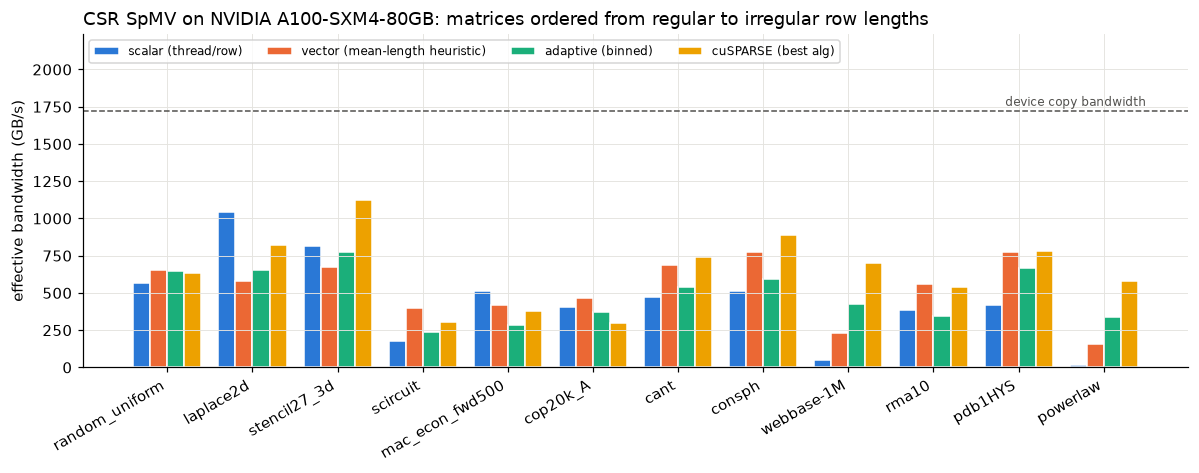

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.4))
order = list(tab.index)
cols = [("scalar", "scalar (thread/row)"), ("vector_heuristic", "vector (mean-length heuristic)"),
        ("adaptive", "adaptive (binned)"), ("cusparse", "cuSPARSE (best alg)")]
w = 0.2
for i, (k, lab) in enumerate(cols):
    gbs = nbytes.reindex(order) / (tab[f"{k}_us"] * 1e-6) / 1e9
    ax.bar(np.arange(len(order)) + (i - 1.5) * w, gbs, w, color=SERIES[i], label=lab, edgecolor="white", linewidth=1)
ax.axhline(dev["copy_gbs"], color="#52514e", ls="--", lw=1)
ax.text(len(order) - 0.5, dev["copy_gbs"] * 1.02, "device copy bandwidth", ha="right", fontsize=8, color="#52514e")
ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
ax.set_ylabel("effective bandwidth (GB/s)")
ax.set_title(f"CSR SpMV on {GPU}: matrices ordered from regular to irregular row lengths", loc="left")
ax.set_ylim(0, dev["copy_gbs"] * 1.3)
ax.legend(ncol=4, fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(OUT / "spmv_bandwidth.png", bbox_inches="tight"); plt.show()

## 5 · Floating-point error analysis
Maximum componentwise error per row-length class, in units of `u = 2^-24`. A sequential sum of `n` products has a worst-case bound of about `n·u`; a tree (warp-shuffle) reduction over 32 lanes about `(n/32 + 5)·u`.

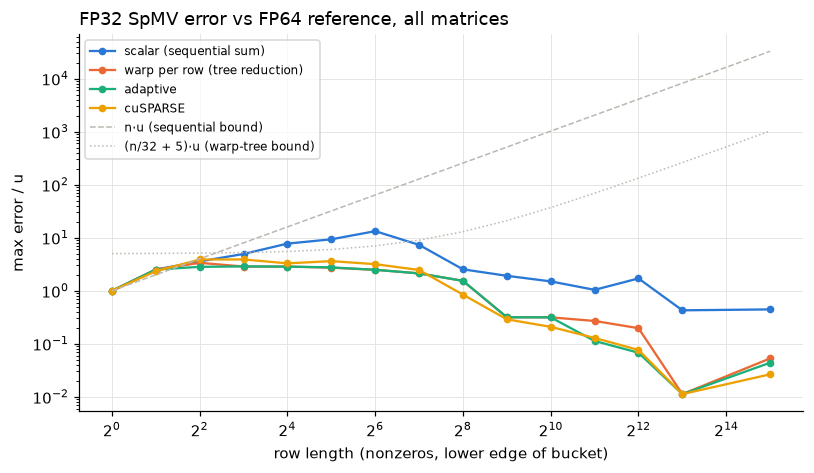

kernel,adaptive,cusparse_csr_alg2,cusparse_default,scalar,vector16,vector2,vector32,vector4,vector8
matrix,,,,,,,,,
cant,1.89,2.43,2.43,4.96,1.76,3.20,1.89,2.81,1.77
consph,1.85,2.18,2.18,6.74,1.78,3.29,1.85,2.35,1.87
cop20k_A,2.08,2.76,2.76,9.13,2.08,3.86,2.08,3.58,2.57
laplace2d,2.09,2.84,2.84,2.75,2.09,2.49,2.09,2.09,2.09
mac_econ_fwd500,2.82,3.89,3.89,5.96,3.36,4.26,3.36,3.62,3.36
pdb1HYS,2.12,2.63,2.63,7.33,2.54,5.45,2.12,3.98,2.83
powerlaw,2.61,2.89,2.89,3.62,2.55,2.44,2.55,2.61,2.55
random_uniform,2.01,2.66,2.66,3.43,2.20,2.64,2.20,2.07,2.01
rma10,2.88,3.62,3.62,13.29,3.19,8.62,2.78,4.46,3.85


In [9]:
agg = errb.groupby(["kernel", "log2len"])["max_err_u"].max().unstack(0)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
lens = 2.0 ** agg.index.values
names = {"scalar": "scalar (sequential sum)", "vector32": "warp per row (tree reduction)",
         "adaptive": "adaptive", "cusparse_default": "cuSPARSE"}
for i, k in enumerate(["scalar", "vector32", "adaptive", "cusparse_default"]):
    if k in agg:
        ax.plot(lens, agg[k].values, marker="o", ms=4, color=SERIES[i], label=names[k])
ax.plot(lens, lens, color="#b9b8b2", ls="--", lw=1, label="n·u (sequential bound)")
ax.plot(lens, lens / 32 + 5, color="#b9b8b2", ls=":", lw=1, label="(n/32 + 5)·u (warp-tree bound)")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("row length (nonzeros, lower edge of bucket)"); ax.set_ylabel("max error / u")
ax.set_title("FP32 SpMV error vs FP64 reference, all matrices", loc="left"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "spmv_error.png", bbox_inches="tight"); plt.show()
res.pivot(index="matrix", columns="kernel", values="max_err_u").round(2)

## 6 · cuTile Python SpMV (Ampere or newer)

In [10]:
%%writefile spmv_cutile.py
"""cuTile Python SpMV (CSR). Needs an Ampere-or-newer GPU and `pip install cuda-tile[tileiras]`."""
import cuda.tile as ct


@ct.kernel
def spmv_csr_tile(row_ids, row_ptr, col_idx, vals, x, y, n_rows, max_len,
                  R: ct.Constant[int], W: ct.Constant[int]):
    # One block owns R rows of a row-length group; each loop step gathers an R x W tile of nonzeros.
    pid = ct.bid(0)
    lane = ct.arange(R, dtype=ct.int32) + pid * R
    rmask = lane < n_rows
    rows = ct.gather(row_ids, lane, mask=rmask, padding_value=0)
    start = ct.expand_dims(ct.gather(row_ptr, rows), 1)          # (R, 1)
    end = ct.expand_dims(ct.gather(row_ptr, rows + 1), 1)
    rmask2 = ct.expand_dims(rmask, 1)
    off = ct.expand_dims(ct.arange(W, dtype=ct.int32), 0)         # (1, W)
    acc = ct.zeros((R,), dtype=ct.float32)
    for j in range(0, max_len, W):
        k = start + off + j                                       # (R, W) CSR positions
        m = (k < end) & rmask2
        c = ct.gather(col_idx, k, mask=m, padding_value=0)
        v = ct.gather(vals, k, mask=m, padding_value=0.0)
        xv = ct.gather(x, c, mask=m, padding_value=0.0)
        acc = acc + ct.sum(v * xv, axis=1)
    ct.scatter(y, rows, acc, mask=rmask)


def spmv(groups, row_ptr, col_idx, vals, x, y, stream):
    """y = A x: one launch per row-length group, each a specialization of the same kernel."""
    for g in groups:
        grid = ((g["n"] + g["R"] - 1) // g["R"], 1, 1)
        ct.launch(stream, grid, spmv_csr_tile,
                  (g["rows_dev"], row_ptr, col_idx, vals, x, y, g["n"], g["max_len"], g["R"], g["W"]))

Overwriting spmv_cutile.py


In [11]:
cut = pd.DataFrame()
cc_major = int(str(dev["cc"]).split(".")[0])
if SKIP_CUTILE:
    print("cuTile part skipped (SPMV_SKIP_CUTILE=1)")
elif cc_major < 8:
    print(f"cuTile needs compute capability 8.0+; this GPU is {dev['cc']}. Run on an A100 / L4 / H100 for this part.")
else:
    try:
        import cuda.tile  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cuda-tile[tileiras]"], check=True)
    import torch
    import spmv_cutile as CT
    importlib.reload(CT)
    from torch.profiler import profile, ProfilerActivity
    stream = torch.cuda.current_stream()
    flush = torch.empty(max(4 * dev["l2"], 256 << 20), dtype=torch.uint8, device="cuda")
    rows_out = []
    for name, (A, desc, src) in mats.items():
        x = L.bench_x_fast(A.shape[1])
        ref = A.astype(np.float64) @ x.astype(np.float64)
        aref = abs(A.astype(np.float64)) @ np.abs(x.astype(np.float64))
        groups = L.cutile_groups(A.indptr)
        for g in groups:
            g["rows_dev"] = torch.from_numpy(g["rows"]).cuda()
        rp, ci = torch.from_numpy(A.indptr).cuda(), torch.from_numpy(A.indices).cuda()
        v, xd = torch.from_numpy(A.data).cuda(), torch.from_numpy(x).cuda()
        y = torch.full((A.shape[0],), float("nan"), device="cuda")
        run = lambda: CT.spmv(groups, rp, ci, v, xd, y, stream)  # noqa: E731
        t0 = time.time(); run(); torch.cuda.synchronize(); first_s = time.time() - t0   # includes JIT compile
        yh = y.cpu().numpy()
        err = np.where(aref > 0, np.abs(yh - ref) / np.where(aref > 0, aref, 1), np.abs(yh)) / 2.0**-24
        for _ in range(3):
            run()
        ts = []
        s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        for i in range(30):
            flush.fill_(i & 255); s.record(); run(); e.record(); e.synchronize()
            ts.append(s.elapsed_time(e) * 1e3)
        dev_us = np.nan
        try:                                   # pure GPU time of the cuTile kernels (no Python launch gaps)
            with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as prof:
                for _ in range(10):
                    run()
                torch.cuda.synchronize()
            ks = [ev for ev in prof.events() if str(ev.device_type).endswith("CUDA")
                  and not ev.name.lower().startswith(("memset", "memcpy"))]
            if ks:
                dev_us = sum(ev.time_range.end - ev.time_range.start for ev in ks) / 10
        except Exception as ex:
            print("profiler unavailable:", str(ex)[:80])
        rows_out.append(dict(matrix=name, groups=len(groups), cutile_us=float(np.median(ts)), cutile_device_us=dev_us,
                             first_call_s=first_s, max_err_u=float(np.nanmax(err)), nan_rows=int(np.isnan(yh).sum())))
        print(f"  {name:16s} {len(groups):2d} launches  median {np.median(ts):9.1f} us  device {dev_us:9.1f} us  "
              f"max err {np.nanmax(err):6.2f} u  (first call {first_s:.1f}s incl. JIT)")
    cut = pd.DataFrame(rows_out).set_index("matrix")
    cut["adaptive_cuda_us"] = tab["adaptive_us"]; cut["cusparse_us"] = tab["cusparse_us"]
    cut["device_vs_cusparse"] = cut["cusparse_us"] / cut["cutile_device_us"]
    cut["device_vs_adaptive_cuda"] = cut["adaptive_cuda_us"] / cut["cutile_device_us"]
    cut.to_csv(OUT / "cutile.csv")
    display(cut.round(2))

USDT:2026-11-03 00:24:30 3432250:3432250 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-03 00:24:30 3432250:3432250 SyncActivityProfilerHandler.cpp:46] profiler_stop


  laplace2d         2 launches  median     167.9 us  device     157.6 us  max err   2.09 u  (first call 0.4s incl. JIT)


USDT:2026-11-03 00:24:31 3432250:3432250 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-03 00:24:31 3432250:3432250 SyncActivityProfilerHandler.cpp:46] profiler_stop


  stencil27_3d      3 launches  median     398.5 us  device     388.7 us  max err   1.77 u  (first call 0.2s incl. JIT)


USDT:2026-11-03 00:24:31 3432250:3432250 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-03 00:24:31 3432250:3432250 SyncActivityProfilerHandler.cpp:46] profiler_stop


  random_uniform    1 launches  median     453.5 us  device     448.8 us  max err   2.20 u  (first call 0.1s incl. JIT)


... (11 outputs left out)

  mac_econ_fwd500   5 launches  median      72.4 us  device      40.4 us  max err   3.36 u  (first call 0.7s incl. JIT)
  scircuit          8 launches  median      85.9 us  device      48.3 us  max err   2.88 u  (first call 0.0s incl. JIT)


  webbase-1M       11 launches  median     293.2 us  device     274.4 us  max err   2.59 u  (first call 1.1s incl. JIT)


USDT:2026-11-03 00:24:43 3432250:3432250 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-11-03 00:24:43 3432250:3432250 SyncActivityProfilerHandler.cpp:46] profiler_stop


,groups,cutile_us,cutile_device_us,first_call_s,max_err_u,nan_rows,adaptive_cuda_us,cusparse_us,device_vs_cusparse,device_vs_adaptive_cuda
matrix,,,,,,,,,,
laplace2d,2,167.89,157.61,0.43,2.09,0,83.52,66.08,0.42,0.53
stencil27_3d,3,398.53,388.69,0.16,1.77,0,146.91,101.47,0.26,0.38
random_uniform,1,453.54,448.76,0.05,2.20,0,215.84,221.25,0.49,0.48
powerlaw,11,903.10,887.15,0.26,2.55,0,233.73,135.23,0.15,0.26
cant,4,150.46,128.65,2.59,1.92,0,60.90,44.42,0.35,0.47
pdb1HYS,4,114.74,97.56,1.09,1.91,0,52.86,44.93,0.46,0.54
rma10,7,115.39,66.68,1.35,2.92,0,56.13,36.22,0.54,0.84
cop20k_A,6,131.50,80.11,0.00,2.37,0,60.03,74.91,0.94,0.75
consph,5,201.65,183.80,3.26,1.80,0,82.43,55.30,0.30,0.45


## 7 · Summary (paste this back)

In [12]:
gm = lambda s: float(np.exp(np.log(np.asarray(s, float)).mean()))  # noqa: E731
real = minfo[minfo.source == "SuiteSparse"]["matrix"].tolist()
irr = tab.index[(info.loc[tab.index, "std_len"] / info.loc[tab.index, "mean_len"]) > 1.0].tolist()
agg_big = agg.dropna(subset=["scalar", "vector32"])
lb = agg_big.index.max() if len(agg_big) else None
lines = [
    f"# SpMV summary: {GPU} (cc {dev['cc']}, copy BW {dev['copy_gbs']:.0f} GB/s)",
    f"* Matrices: {len(mats)} ({len(real)} SuiteSparse: {', '.join(real)}; {len(mats) - len(real)} synthetic); "
    f"largest {int(info['nnz'].max()):,} nnz; max row length {int(info['max_len'].max()):,}.",
    f"* Correctness: {'all kernels within FP32 error bounds of the FP64 reference' if bad.empty else 'FAILURES, see section 3'}.",
    f"* Adaptive vs scalar: geomean {gm(tab['adaptive_vs_scalar']):.2f}x, max {tab['adaptive_vs_scalar'].max():.2f}x "
    f"({tab['adaptive_vs_scalar'].idxmax()}).",
    f"* Adaptive vs cuSPARSE (best of 2 algs): geomean {gm(tab['adaptive_vs_cusparse']):.2f}x of cuSPARSE throughput; "
    f"within 10% or faster on {(tab['adaptive_vs_cusparse'] >= 0.9).sum()}/{len(tab)} matrices; "
    f"faster on {(tab['adaptive_vs_cusparse'] > 1).sum()}/{len(tab)}.",
    f"* Adaptive bandwidth: median {tab['adaptive_%copyBW'].median():.0f}% of device copy bandwidth, "
    f"max {tab['adaptive_%copyBW'].max():.0f}% ({tab['adaptive_%copyBW'].idxmax()}).",
    f"* Irregular matrices (row-length CV > 1: {', '.join(irr) or 'none'}): adaptive vs best single vector kernel "
    + (f"geomean {gm(tab.loc[irr, 'vector_best_us'] / tab.loc[irr, 'adaptive_us']):.2f}x." if irr else "n/a."),
    f"* Mean-length heuristic vs autotuned threads-per-row: heuristic is {gm(tab['vector_heuristic_us'] / tab['vector_best_us']):.2f}x "
    f"slower on geomean; it picked the best T on {(tab['heuristic_T'] == tab['autotuned_T']).sum()}/{len(tab)} matrices.",
]
if lb is not None:
    lines.append(f"* Error, rows with >= {2**int(lb):,} nonzeros: scalar {agg_big.loc[lb, 'scalar']:.1f}u vs warp tree "
                 f"{agg_big.loc[lb, 'vector32']:.1f}u ({agg_big.loc[lb, 'scalar'] / max(agg_big.loc[lb, 'vector32'], 1e-9):.1f}x lower); "
                 f"max over all kernels/matrices {res['max_err_u'].max():.1f}u.")
if len(cut):
    lines.append(f"* cuTile ({len(cut)} matrices): max error {cut['max_err_u'].max():.2f}u, NaN rows {int(cut['nan_rows'].sum())}; "
                 f"device time geomean {gm(cut['device_vs_cusparse'].dropna()):.2f}x of cuSPARSE throughput and "
                 f"{gm(cut['device_vs_adaptive_cuda'].dropna()):.2f}x of the CUDA C++ adaptive kernel; "
                 f"{int(cut['groups'].median())} specialized launches per SpMV (median).")
text = "\n".join(lines)
(OUT / "SUMMARY.md").write_text(text + "\n")
print(text)
print("\nPer-matrix table:"); print(tab[["adaptive_us", "cusparse_us", "cusparse_alg", "adaptive_vs_cusparse",
                                       "adaptive_%copyBW", "adaptive_vs_scalar", "autotuned_T", "heuristic_T"]].round(2).to_string())
zname = f"spmv_results_{OUT.name}.zip"
with zipfile.ZipFile(zname, "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        z.write(f, f"{OUT.name}/{f.name}")
print(f"\nSaved {zname} (download it and send it back with this summary)")

# SpMV summary: NVIDIA A100-SXM4-80GB (cc 8.0, copy BW 1721 GB/s)
* Matrices: 12 (8 SuiteSparse: cant, pdb1HYS, rma10, cop20k_A, consph, mac_econ_fwd500, scircuit, webbase-1M; 4 synthetic); largest 15,999,878 nnz; max row length 48,795.
* Correctness: all kernels within FP32 error bounds of the FP64 reference.
* Adaptive vs scalar: geomean 1.51x, max 18.51x (powerlaw).
* Adaptive vs cuSPARSE (best of 2 algs): geomean 0.76x of cuSPARSE throughput; within 10% or faster on 2/12 matrices; faster on 2/12.
* Adaptive bandwidth: median 28% of device copy bandwidth, max 45% (stencil27_3d).
* Irregular matrices (row-length CV > 1: webbase-1M, powerlaw): adaptive vs best single vector kernel geomean 1.50x.
* Mean-length heuristic vs autotuned threads-per-row: heuristic is 1.27x slower on geomean; it picked the best T on 1/12 matrices.
* Error, rows with >= 32,768 nonzeros: scalar 0.4u vs warp tree 0.1u (8.4x lower); max over all kernels/matrices 13.3u.
* cuTile (12 matrices): max error 3.36u, Na